# Exercise 4 - One spherical collapse, three numerical formulations

Flat $\Lambda$CDM and EdS, smooth $\Lambda$, no shear, no radiation (Lecture 8, notes Sections 3, 6-7; Pace, Meyer & Bartelmann 2017).
Code: `Library/exercise_4.py`. Saved data, figures and LaTeX tables: `results/exercise_4/`.

In [1]:
%matplotlib widget
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../Library")
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import exercise_1 as ex1
import exercise_4 as ex4

# Folder for the saved data, figures and LaTeX tables of this exercise
out_dir = "../results/exercise_4"
os.makedirs(out_dir, exist_ok=True)

# Exact EdS benchmarks (notes eqs. 2.9, 2.15, 2.16, 3.6)
delta_c_EdS = 3.0 / 20.0 * (12.0 * np.pi)**(2.0 / 3.0)   # 1.68647...
ata_ac_EdS = 2.0**(-2.0 / 3.0)                           # a_ta / a_c
zeta_ta_EdS = (3.0 * np.pi / 4.0)**2                     # 1 + delta at turnaround
Dvir_EdS = 18.0 * np.pi**2                               # Delta_vir,m = Delta_vir,c in EdS

# Default settings used everywhere unless stated (see ex4.spherical_collapse)
a_i_def, rtol_def, atol_def = 1e-5, 1e-10, 1e-14

In [2]:
# Small helper: save a DataFrame as CSV (data) and as a LaTeX table (for the report)
def save_table(df, name, formatters=None, rename=None):
    df.to_csv(f"{out_dir}/{name}.csv", index=False)
    df_tex = df.rename(columns=rename) if rename else df
    fmt = {rename.get(k, k): v for k, v in formatters.items()} if (rename and formatters) else formatters
    df_tex.to_latex(f"{out_dir}/{name}.tex", index=False, formatters=fmt, escape=False)

## (a) The three systems

$$A_H = 2 + \frac{d\ln H}{dN},\qquad \vartheta = \frac{\nabla_x\cdot v}{aH},\qquad g = \frac{1}{\delta}$$

- **A**: $\delta_{NN} + A_H\delta_N - \frac{4}{3}\frac{\delta_N^2}{1+\delta} - \frac{3}{2}\Omega_m\delta(1+\delta) = 0$ (solved as $[\delta, \delta_N]$)
- **B**: $\delta_N = -(1+\delta)\vartheta,\quad \vartheta_N = -A_H\vartheta - \vartheta^2/3 - \frac{3}{2}\Omega_m\delta$
- **C**: $g_N = g(1+g)\vartheta,\quad \vartheta_N = -A_H\vartheta - \vartheta^2/3 - \frac{3\Omega_m}{2g}$

Each one has its own right-hand side (`rhs_A`, `rhs_B`, `rhs_C`) and its own integration.

**Algebraic equivalence.** At random states we check that (i) differentiating B's first equation, $\delta_{NN} = -\delta_N\vartheta - (1+\delta)\vartheta_N$, gives A's $\delta_{NN}$, and (ii) with $g = 1/\delta$, C gives $g_N = -\delta_N/\delta^2$ and the same $\vartheta_N$ as B.

In [3]:
# Random test states (N, delta, theta) covering the range met during a collapse
rng = np.random.default_rng(42)
Om0 = 0.3
err_A, err_gN, err_thN = [], [], []

for _ in range(1000):
    N = rng.uniform(np.log(1e-5), 0.0)
    delta = 10**rng.uniform(-5, 8)           # from linear to deep nonlinear
    theta = -10**rng.uniform(-5, 4)          # theta < 0 for a collapsing sphere

    # B: delta_N and theta_N
    dN_B, thN_B = ex4.rhs_B(N, [delta, theta], Om0)

    # (i) delta_NN from A (using B's delta_N) vs derivative of B's continuity equation
    dNN_A = ex4.rhs_A(N, [delta, dN_B], Om0)[1]
    dNN_B = -dN_B * theta - (1.0 + delta) * thN_B
    err_A.append(abs(dNN_A / dNN_B - 1))

    # (ii) C at g = 1/delta: g_N must equal -delta_N/delta^2 and theta_N must equal B's
    gN_C, thN_C = ex4.rhs_C(N, [1.0 / delta, theta], Om0)
    err_gN.append(abs(gN_C / (-dN_B / delta**2) - 1))
    err_thN.append(abs(thN_C / thN_B - 1))

print(f"A  vs B : max rel. diff in delta_NN = {max(err_A):.1e}")
print(f"C  vs B : max rel. diff in g_N      = {max(err_gN):.1e}")
print(f"C  vs B : max rel. diff in theta_N  = {max(err_thN):.1e}")

A  vs B : max rel. diff in delta_NN = 7.1e-15
C  vs B : max rel. diff in g_N      = 4.4e-16
C  vs B : max rel. diff in theta_N  = 1.3e-15


**Independent integrations.** Same $\delta_i$, cosmology and settings for A, B and C; we compare the resulting $\delta(a)$ (C uses $\delta = 1/g$) and plot the linear solution $\delta_L$ alongside.

In [4]:
# Flat LCDM, Om0 = 0.3. Tune delta_i once (with B) so that collapse happens at a_c = 1
Om0, z_c = 0.3, 0.0
a_c = 1.0 / (1.0 + z_c)
delta_i = ex4.spherical_collapse("B", z_c, Om0)["delta_i"]

# Integrate each formulation independently, keeping a continuous (dense) solution
N_end = np.log(2.0 * a_c)
sols = {}
for form in "ABC":
    sols[form] = ex4.integrate_nonlinear(form, delta_i, Om0, a_i_def, N_end,
                                         ex4.default_threshold(form), rtol_def, atol_def,
                                         dense_output=True)

# Common N grid: from a_i up to just before the earliest collapse event
N_stop = min(s.t_events[0][0] for s in sols.values())
N = np.linspace(np.log(a_i_def), N_stop - 1e-4, 4000)
a = np.exp(N)

# delta(a) from each formulation (C stores g = 1/delta)
delta_A = sols["A"].sol(N)[0]
delta_B = sols["B"].sol(N)[0]
delta_C = 1.0 / sols["C"].sol(N)[0]

# Linear solution with the same initial amplitude
delta_L = ex4.linear_delta(delta_i, Om0, a_i_def, a, rtol_def, atol_def)

# Turnaround epoch (theta = -3) from B
a_ta = np.exp(sols["B"].t_events[1][0])

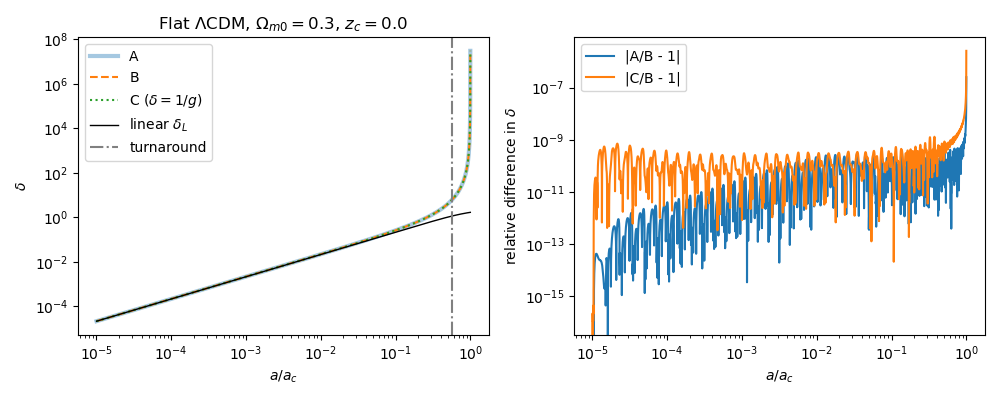

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Left: nonlinear delta from A, B, C and the linear delta_L
ax[0].loglog(a / a_c, delta_A, lw=3, alpha=0.4, label="A")
ax[0].loglog(a / a_c, delta_B, "--", label="B")
ax[0].loglog(a / a_c, delta_C, ":", label=r"C ($\delta = 1/g$)")
ax[0].loglog(a / a_c, delta_L, "k-", lw=1, label=r"linear $\delta_L$")
ax[0].axvline(a_ta / a_c, color="gray", ls="-.", label="turnaround")
ax[0].set_xlabel("$a/a_c$")
ax[0].set_ylabel(r"$\delta$")
ax[0].set_title(rf"Flat $\Lambda$CDM, $\Omega_{{m0}}={Om0}$, $z_c={z_c}$")
ax[0].legend()

# Right: relative differences between the independent integrations
ax[1].loglog(a / a_c, np.abs(delta_A / delta_B - 1), label="|A/B - 1|")
ax[1].loglog(a / a_c, np.abs(delta_C / delta_B - 1), label="|C/B - 1|")
ax[1].set_xlabel("$a/a_c$")
ax[1].set_ylabel("relative difference in $\\delta$")
ax[1].legend()

plt.tight_layout()
fig.savefig(f"{out_dir}/fig_trajectories.pdf")
plt.show()

## (b) Growing-mode initial conditions

$$\delta_{N,i} = f_i\delta_i,\qquad \vartheta_i = -\frac{f_i\delta_i}{1+\delta_i},\qquad g_i = \delta_i^{-1},\qquad \delta_{L,i} = \delta_i,\quad \delta_{L,N,i} = f_i\delta_i$$

$f_i$ comes from the Exercise 1 growth ODE (`ex1.growth_ode`), started at $a_i/100$ so that $f_i$ is not just its own initial condition.

In [6]:
# 1 - f_i for the cosmologies and initial epochs used in this exercise
for Om0 in [1.0, 0.2, 0.3, 0.4]:
    line = "  ".join(f"a_i={a_i:.0e}: {1 - ex4.growth_rate_initial(a_i, Om0):.1e}"
                     for a_i in [1e-3, 1e-4, 1e-5])
    print(f"Om0 = {Om0}:  1 - f_i ->  {line}")

Om0 = 1.0:  1 - f_i ->  a_i=1e-03: 0.0e+00  a_i=1e-04: 0.0e+00  a_i=1e-05: 2.2e-16
Om0 = 0.2:  1 - f_i ->  a_i=1e-03: 2.2e-09  a_i=1e-04: 2.2e-12  a_i=1e-05: 2.2e-15
Om0 = 0.3:  1 - f_i ->  a_i=1e-03: 1.3e-09  a_i=1e-04: 1.3e-12  a_i=1e-05: 1.6e-15
Om0 = 0.4:  1 - f_i ->  a_i=1e-03: 8.2e-10  a_i=1e-04: 8.2e-13  a_i=1e-05: 6.7e-16


## (c) Shooting for the collapse epoch

- Terminal event: $\delta = \delta_\infty$ (A, B) or $g = \epsilon$ (C); the integration stops there and never crosses the singularity.
- Root function: $F(\delta_i) = N_\mathrm{event}(\delta_i) - \ln a_c$, solved with Brent's method inside a bracket found by expanding around the linear guess $1.686\,D(a_i)/D(a_c)$.
- $\delta_c = \delta_L(a_c)$ from the linear solution with the tuned $\delta_i$.

Defaults: $a_i = 10^{-5}$, `DOP853`, `rtol` $=10^{-10}$, `atol` $=10^{-14}$, $\delta_\infty = 10^8$, $\epsilon = 10^{-8}$.

In [7]:
# Required outputs of each formulation for EdS and flat LCDM (Om0 = 0.3), z_c = 0
rows = []
for Om0 in [1.0, 0.3]:
    for form in "ABC":
        r = ex4.spherical_collapse(form, 0.0, Om0)
        rows.append({"Om0": Om0, "form": form, "delta_i": r["delta_i"],
                     "bracket_lo": r["bracket"][0], "bracket_hi": r["bracket"][1],
                     "n_iter": r["n_iter"], "residual_lna": r["event_residual_N"],
                     "a_ta": r["a_ta"], "zeta_ta": r["zeta_ta"], "delta_c": r["delta_c"],
                     "Dvir_m": r["Dvir_m"], "Dvir_c": r["Dvir_c"]})

df_out = pd.DataFrame(rows)
pd.set_option("display.precision", 8)
df_out

,Om0,form,delta_i,bracket_lo,bracket_hi,n_iter,residual_lna,a_ta,zeta_ta,delta_c,Dvir_m,Dvir_c
0,1.0,A,0.00001686,0.00001517,0.00001855,7,-5.88023787e-16,0.63000260,5.55165248,1.6863898,177.61728923,177.61728923
1,1.0,B,0.00001686,0.00001517,0.00001855,7,-5.44495033e-17,0.63000260,5.55165248,1.6863898,177.61728924,177.61728924
2,1.0,C,0.00001686,0.00001517,0.00001855,6,1.28323118e-15,0.63000260,5.55165248,1.6863898,177.61728923,177.61728923
3,0.3,A,0.00002151,0.00001948,0.00002381,7,-4.03064922e-15,0.56146175,6.83730770,1.6754604,339.71423062,101.91426918
4,0.3,B,0.00002151,0.00001948,0.00002381,7,-1.56046144e-16,0.56146175,6.83730770,1.6754604,339.71423061,101.91426918
5,0.3,C,0.00002151,0.00001948,0.00002381,7,-6.36132248e-16,0.56146175,6.83730770,1.6754604,339.71423057,101.91426917


In [8]:
# Save the table (CSV + LaTeX)
save_table(df_out, "tab_outputs_zc0",
           formatters={"Om0": "{:.1f}".format, "delta_i": "{:.10e}".format,
                       "bracket_lo": "{:.4e}".format, "bracket_hi": "{:.4e}".format,
                       "n_iter": "{:d}".format, "residual_lna": "{:.1e}".format,
                       "a_ta": "{:.6f}".format, "zeta_ta": "{:.6f}".format,
                       "delta_c": "{:.6f}".format, "Dvir_m": "{:.3f}".format,
                       "Dvir_c": "{:.3f}".format},
           rename={"Om0": r"$\Omega_{m0}$", "delta_i": r"$\delta_i$",
                   "bracket_lo": "bracket lo", "bracket_hi": "bracket hi",
                   "n_iter": "iter.", "residual_lna": r"$\ln(a_\mathrm{ev}/a_c)$",
                   "a_ta": r"$a_\mathrm{ta}$", "zeta_ta": r"$\zeta_\mathrm{ta}$",
                   "delta_c": r"$\delta_c$", "Dvir_m": r"$\Delta_{\mathrm{vir},m}$",
                   "Dvir_c": r"$\Delta_{\mathrm{vir},c}$"})

**Finite-threshold limit** (EdS, $z_c=0$, exact values known). We use $\epsilon = 1/\delta_\infty$ so the three events are the same physical condition.
Near collapse the cycloid (notes eq. 2.6) gives $R \propto (t_c-t)^{2/3}$, i.e. $\delta \propto (t_c - t)^{-2}$: the event comes early by $\Delta t/t_c \propto \delta_\infty^{-1/2}$.

In [9]:
thresholds = [1e5, 1e6, 1e7, 1e8]       # delta_inf; for C we use eps = 1/delta_inf
err_dc = {form: [] for form in "ABC"}
err_ta = {form: [] for form in "ABC"}

for form in "ABC":
    for d_inf in thresholds:
        th = d_inf if form in "AB" else 1.0 / d_inf
        r = ex4.spherical_collapse(form, 0.0, 1.0, threshold=th)
        err_dc[form].append(r["delta_c"] / delta_c_EdS - 1)
        err_ta[form].append(r["a_ta/a_c"] / ata_ac_EdS - 1)

for form in "ABC":
    print(form, " delta_c rel. err:", " ".join(f"{e:+.2e}" for e in err_dc[form]))

A  delta_c rel. err: -2.12e-03 -6.53e-04 -1.92e-04 -4.77e-05
B  delta_c rel. err: -2.12e-03 -6.53e-04 -1.92e-04 -4.77e-05
C  delta_c rel. err: -2.12e-03 -6.53e-04 -1.92e-04 -4.77e-05


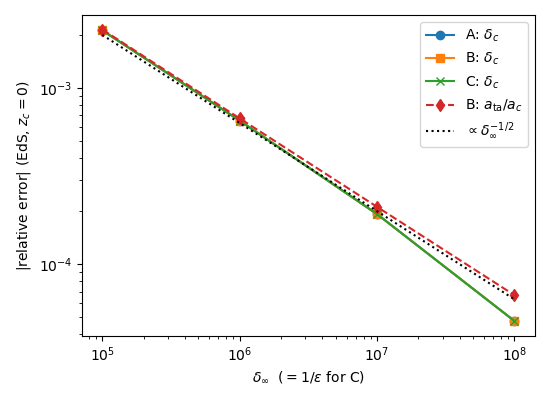

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 4))

# |relative error| vs threshold, for each formulation
for form, mk in zip("ABC", ["o", "s", "x"]):
    ax.loglog(thresholds, np.abs(err_dc[form]), mk + "-", label=rf"{form}: $\delta_c$")
ax.loglog(thresholds, np.abs(err_ta["B"]), "d--", label=r"B: $a_\mathrm{ta}/a_c$")

# Reference slope delta_inf^(-1/2)
th = np.array(thresholds)
ax.loglog(th, 2e-3 * (th / 1e5)**-0.5, "k:", label=r"$\propto \delta_\infty^{-1/2}$")

ax.set_xlabel(r"$\delta_\infty$  ($=1/\epsilon$ for C)")
ax.set_ylabel("|relative error| (EdS, $z_c=0$)")
ax.legend()
plt.tight_layout()
fig.savefig(f"{out_dir}/fig_threshold.pdf")
plt.show()

The error follows $\delta_\infty^{-1/2}$; at $\delta_\infty = 10^8$ the remaining part ($\sim 10^{-5}$) also contains the $a_i$ error (see (g)). A, B and C give the same numbers: the threshold bias is a property of the event, not of the formulation.

## (d) Turnaround and virial prescription

- Turnaround: event $\vartheta = -3$ (A: $\vartheta = -\delta_N/(1+\delta)$; C: $\delta = 1/g$), $\zeta_\mathrm{ta} = 1 + \delta(a_\mathrm{ta})$.
- $\lambda_\mathrm{ta} = \rho_\Lambda/\rho_\mathrm{sph,ta} = \Omega_\Lambda(a_\mathrm{ta})/[\Omega_m(a_\mathrm{ta})\zeta_\mathrm{ta}]$ and $4\lambda_\mathrm{ta}y^3 - 2(1+\lambda_\mathrm{ta})y + 1 = 0$.
- The cubic is $+1$ at $y=0$ and $-\lambda/2$ at $y=1/2$, so the root connected to $y=1/2$ is the one in $(0, 1/2]$ (found with `brentq`).

$$\Delta_{\mathrm{vir},m} = \zeta_\mathrm{ta}\left(\frac{a_c}{a_\mathrm{ta}}\right)^3 y^{-3},\qquad \Delta_{\mathrm{vir},c} = \Omega_m(a_c)\Delta_{\mathrm{vir},m}$$

In [11]:
# y(lambda) must go continuously to 1/2 as lambda -> 0
for lam in [0.0, 1e-6, 1e-3, 1e-2, 0.1]:
    y = ex4.virial_y(lam)
    print(f"lambda = {lam:.0e}:  y = {y:.8f},  cubic residual = {4*lam*y**3 - 2*(1+lam)*y + 1:.1e}")

lambda = 0e+00:  y = 0.50000000,  cubic residual = 0.0e+00
lambda = 1e-06:  y = 0.49999975,  cubic residual = 0.0e+00
lambda = 1e-03:  y = 0.49974988,  cubic residual = -2.2e-16
lambda = 1e-02:  y = 0.49748763,  cubic residual = 5.6e-16
lambda = 1e-01:  y = 0.47389566,  cubic residual = 0.0e+00


In [12]:
# lambda_ta and y for the flat LCDM runs of (c) (Om0 = 0.3, z_c = 0)
for form in "ABC":
    r = ex4.spherical_collapse(form, 0.0, 0.3)
    print(f"{form}: a_ta/a_c = {r['a_ta/a_c']:.8f}, zeta_ta = {r['zeta_ta']:.8f}, "
          f"lambda_ta = {r['lambda_ta']:.6f}, y = {r['y']:.8f}")

A: a_ta/a_c = 0.56146175, zeta_ta = 6.83730770, lambda_ta = 0.060402, y = 0.48447379
B: a_ta/a_c = 0.56146175, zeta_ta = 6.83730770, lambda_ta = 0.060402, y = 0.48447379


C: a_ta/a_c = 0.56146175, zeta_ta = 6.83730770, lambda_ta = 0.060402, y = 0.48447379


## (e) EdS benchmarks at several collapse redshifts

Targets: $\delta_c = 1.68647$, $a_\mathrm{ta}/a_c = 2^{-2/3}$, $\zeta_\mathrm{ta} = (3\pi/4)^2$, $\Delta_{\mathrm{vir},m} = 18\pi^2$. Table: relative errors.

In [13]:
rows = []
for z_c in [0.0, 1.0, 2.0, 5.0]:
    for form in "ABC":
        r = ex4.spherical_collapse(form, z_c, 1.0)
        rows.append({"z_c": z_c, "form": form,
                     "delta_c": r["delta_c"],
                     "err_delta_c": r["delta_c"] / delta_c_EdS - 1,
                     "err_ata_ac": r["a_ta/a_c"] / ata_ac_EdS - 1,
                     "err_zeta_ta": r["zeta_ta"] / zeta_ta_EdS - 1,
                     "err_Dvir_m": r["Dvir_m"] / Dvir_EdS - 1,
                     "residual_lna": r["event_residual_N"]})

df_eds = pd.DataFrame(rows)
e = "{:+.2e}".format
save_table(df_eds, "tab_eds",
           formatters={"z_c": "{:.0f}".format, "delta_c": "{:.6f}".format,
                       "err_delta_c": e, "err_ata_ac": e, "err_zeta_ta": e,
                       "err_Dvir_m": e, "residual_lna": "{:.1e}".format},
           rename={"z_c": r"$z_c$", "delta_c": r"$\delta_c$",
                   "err_delta_c": r"err $\delta_c$", "err_ata_ac": r"err $a_\mathrm{ta}/a_c$",
                   "err_zeta_ta": r"err $\zeta_\mathrm{ta}$", "err_Dvir_m": r"err $\Delta_{\mathrm{vir},m}$",
                   "residual_lna": r"$\ln(a_\mathrm{ev}/a_c)$"})
df_eds

,z_c,form,delta_c,err_delta_c,err_ata_ac,err_zeta_ta,err_Dvir_m,residual_lna
0,0.0,A,1.68638980,-0.00004767,0.00006679,2.56263899e-11,-0.00020033,-5.88023787e-16
1,0.0,B,1.68638980,-0.00004767,0.00006679,2.07922568e-12,-0.00020033,-5.44495033e-17
2,0.0,C,1.68638980,-0.00004767,0.00006679,-5.28050936e-11,-0.00020033,1.28323118e-15
3,1.0,A,1.68642203,-0.00002856,0.00006679,-1.11117782e-11,-0.00020033,1.11022302e-16
4,1.0,B,1.68642203,-0.00002856,0.00006679,8.52184989e-12,-0.00020033,2.66453526e-15
5,1.0,C,1.68642203,-0.00002856,0.00006679,-4.91326979e-11,-0.00020033,-3.33066907e-16
6,2.0,A,1.68645427,-0.00000945,0.00006679,-1.05511155e-11,-0.00020033,-4.44089210e-16
7,2.0,B,1.68645427,-0.00000945,0.00006679,8.44013748e-12,-0.00020033,0.00000000e+00
8,2.0,C,1.68645427,-0.00000945,0.00006679,-5.79658543e-11,-0.00020033,2.22044605e-16
9,5.0,A,1.68655097,0.00004789,0.00006679,-4.41304771e-11,-0.00020033,-2.22044605e-15


- $\zeta_\mathrm{ta}$ is exact to $\sim 10^{-10}$; $a_\mathrm{ta}/a_c$ ($+6.7\times10^{-5}$) and $\Delta_{\mathrm{vir},m}$ ($-2.0\times10^{-4}$) have the same error at every $z_c$: it is the finite-threshold bias of (c) (event comes early). No threshold was tuned.
- $\delta_c$ has two errors: the threshold bias ($\approx -6.7\times10^{-5}$, constant) plus the initial-epoch error ($\propto \delta_i \propto a_i/a_c$, see (g)), which grows with $z_c$ at fixed $a_i$. This small $z_c$ drift ($\sim 10^{-4}$) is numerical; it disappears as $\delta_\infty \to \infty$ and $a_i \to 0$.

## (f) Flat $\Lambda$CDM grid

$\Omega_{m0}\in\{0.2, 0.3, 0.4\}$, $\Omega_{\Lambda0} = 1-\Omega_{m0}$, all three formulations on a $z_c$ grid that contains $\{0, 1, 2\}$ (extra points only for smooth curves).

In [14]:
z_grid = np.linspace(0.0, 3.0, 13)      # step 0.25: includes the prescribed z_c = 0, 1, 2
Om0_list = [0.2, 0.3, 0.4]

rows = []
for Om0 in Om0_list:
    for z_c in z_grid:
        for form in "ABC":
            r = ex4.spherical_collapse(form, z_c, Om0)
            rows.append({"Om0": Om0, "z_c": z_c, "form": form, "delta_i": r["delta_i"],
                         "residual_lna": r["event_residual_N"], "a_ta": r["a_ta"],
                         "zeta_ta": r["zeta_ta"], "lambda_ta": r["lambda_ta"], "y": r["y"],
                         "delta_c": r["delta_c"], "Dvir_m": r["Dvir_m"], "Dvir_c": r["Dvir_c"]})

df_grid = pd.DataFrame(rows)
df_grid.to_csv(f"{out_dir}/grid_all.csv", index=False)   # data behind the figure

# Largest cross-formulation relative difference over the whole grid
for q in ["delta_c", "zeta_ta", "Dvir_m"]:
    piv = df_grid.pivot_table(index=["Om0", "z_c"], columns="form", values=q)
    spread = (piv.max(axis=1) - piv.min(axis=1)) / piv["B"]
    print(f"max |A-B-C spread| / value in {q:8s}: {spread.max():.1e}")

max |A-B-C spread| / value in delta_c : 1.5e-10
max |A-B-C spread| / value in zeta_ta : 2.2e-10
max |A-B-C spread| / value in Dvir_m  : 1.8e-10


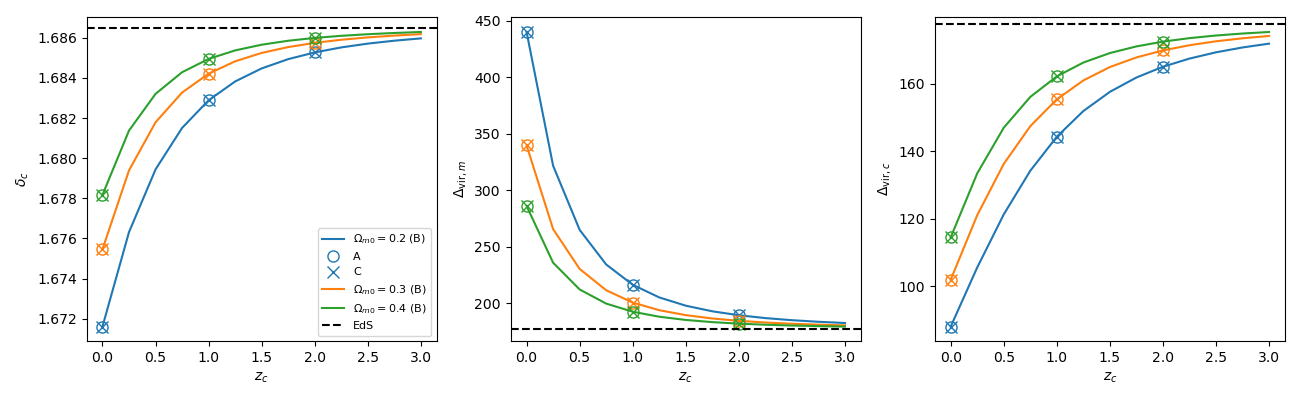

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
quantities = [("delta_c", r"$\delta_c$", delta_c_EdS),
              ("Dvir_m", r"$\Delta_{\mathrm{vir},m}$", Dvir_EdS),
              ("Dvir_c", r"$\Delta_{\mathrm{vir},c}$", Dvir_EdS)]

for k, (q, label, eds) in enumerate(quantities):
    for Om0, color in zip(Om0_list, ["C0", "C1", "C2"]):
        d = df_grid[df_grid.Om0 == Om0]
        # Line: formulation B on the full z grid
        dB = d[d.form == "B"]
        ax[k].plot(dB.z_c, dB[q], color=color, label=rf"$\Omega_{{m0}}={Om0}$ (B)")
        # Markers: A and C at the prescribed z_c = 0, 1, 2
        for form, mk in [("A", "o"), ("C", "x")]:
            dF = d[(d.form == form) & d.z_c.isin([0.0, 1.0, 2.0])]
            ax[k].plot(dF.z_c, dF[q], mk, color=color, mfc="none", ms=8,
                       label=form if Om0 == Om0_list[0] else None)
    # EdS baseline
    ax[k].axhline(eds, color="k", ls="--", label="EdS")
    ax[k].set_xlabel("$z_c$")
    ax[k].set_ylabel(label)

ax[0].legend(fontsize=8)
plt.tight_layout()
fig.savefig(f"{out_dir}/fig_grid.pdf")
plt.show()

In [16]:
# Prescribed grid table (formulation B values; A and C agree to the spread printed above)
df_tab = df_grid[(df_grid.form == "B") & df_grid.z_c.isin([0.0, 1.0, 2.0])]
df_tab = df_tab[["Om0", "z_c", "a_ta", "zeta_ta", "y", "delta_c", "Dvir_m", "Dvir_c"]].copy()
df_tab["a_ta"] = df_tab["a_ta"] * (1 + df_tab["z_c"])      # report a_ta / a_c
df_tab = df_tab.rename(columns={"a_ta": "ata_ac"})

f6 = "{:.6f}".format
save_table(df_tab, "tab_grid",
           formatters={"Om0": "{:.1f}".format, "z_c": "{:.0f}".format, "ata_ac": f6,
                       "zeta_ta": "{:.5f}".format, "y": f6, "delta_c": f6,
                       "Dvir_m": "{:.3f}".format, "Dvir_c": "{:.3f}".format},
           rename={"Om0": r"$\Omega_{m0}$", "z_c": r"$z_c$", "ata_ac": r"$a_\mathrm{ta}/a_c$",
                   "zeta_ta": r"$\zeta_\mathrm{ta}$", "delta_c": r"$\delta_c$",
                   "Dvir_m": r"$\Delta_{\mathrm{vir},m}$", "Dvir_c": r"$\Delta_{\mathrm{vir},c}$"})
df_tab

,Om0,z_c,ata_ac,zeta_ta,y,delta_c,Dvir_m,Dvir_c
1,0.2,0.0,0.53665818,7.44926951,0.47847225,1.67160787,439.99745210,87.99949042
13,0.2,1.0,0.60803540,5.91028645,0.49520136,1.68288644,216.50924083,144.33949388
25,0.2,2.0,0.62266898,5.66660618,0.49841713,1.68527185,189.57124430,165.11043859
40,0.3,0.0,0.56146175,6.83730770,0.48447379,1.67546040,339.71423061,101.91426918
52,0.3,1.0,0.61629077,5.77039486,0.49702485,1.68421202,200.77712761,155.44035686
64,0.3,2.0,0.62562209,5.61976559,0.49905684,1.68574767,184.64261626,169.95513542
79,0.4,0.0,0.57866026,6.46497129,0.48852039,1.67816899,286.18544684,114.47417873
91,0.4,1.0,0.62085562,5.69574506,0.49802277,1.68494668,192.67753897,162.25476966
103,0.4,2.0,0.62715192,5.59579430,0.49938701,1.68599433,182.15108061,172.56418163


**Separating the ingredients.** $\Delta_{\mathrm{vir},m}/18\pi^2$ is a product of three factors, and $\Delta_{\mathrm{vir},c}$ adds $\Omega_m(a_c)$:
$$\frac{\Delta_{\mathrm{vir},m}}{18\pi^2} = \underbrace{\frac{\zeta_\mathrm{ta}}{(3\pi/4)^2}}_{\text{turnaround density}}\times\underbrace{\frac{(a_c/a_\mathrm{ta})^3}{4}}_{\text{ta}\to\text{collapse}}\times\underbrace{\left(\frac{y}{1/2}\right)^{-3}}_{\text{virial (}\Lambda\text{)}}$$

In [17]:
# Factor decomposition for formulation B at the prescribed grid points
dB = df_grid[(df_grid.form == "B") & df_grid.z_c.isin([0.0, 1.0, 2.0])].copy()
dB["f_zeta"] = dB.zeta_ta / zeta_ta_EdS
dB["f_ta_to_c"] = (1.0 / ((1 + dB.z_c) * dB.a_ta))**3 / 4.0
dB["f_virial"] = (dB.y / 0.5)**-3
dB["Om_ac"] = ex4.Omega_m(1.0 / (1 + dB.z_c), dB.Om0)
dB["Dvir_m/18pi2"] = dB.Dvir_m / Dvir_EdS
dB["dc/dc_EdS"] = dB.delta_c / delta_c_EdS
cols = ["Om0", "z_c", "dc/dc_EdS", "f_zeta", "f_ta_to_c", "f_virial", "Dvir_m/18pi2", "Om_ac"]
f4 = "{:.4f}".format
save_table(dB[cols], "tab_decomposition",
           formatters={"Om0": "{:.1f}".format, "z_c": "{:.0f}".format, "dc/dc_EdS": f4,
                       "f_zeta": f4, "f_ta_to_c": f4, "f_virial": f4, "Dvir_m/18pi2": f4, "Om_ac": f4},
           rename={"Om0": r"$\Omega_{m0}$", "z_c": r"$z_c$", "dc/dc_EdS": r"$\delta_c/\delta_c^\mathrm{EdS}$",
                   "f_zeta": r"$\zeta_\mathrm{ta}/\zeta^\mathrm{EdS}_\mathrm{ta}$",
                   "f_ta_to_c": r"$(a_c/a_\mathrm{ta})^3/4$", "f_virial": r"$(2y)^{-3}$",
                   "Dvir_m/18pi2": r"$\Delta_{\mathrm{vir},m}/18\pi^2$", "Om_ac": r"$\Omega_m(a_c)$"})
dB[cols]

,Om0,z_c,dc/dc_EdS,f_zeta,f_ta_to_c,f_virial,Dvir_m/18pi2,Om_ac
1,0.2,0.0,0.99118732,1.34181121,1.61750915,1.14114216,2.47672570,0.20000000
13,0.2,1.0,0.99787500,1.06459950,1.11212451,1.02935343,1.21872070,0.66666667
25,0.2,2.0,0.99928943,1.02070621,1.03554345,1.00955766,1.06708794,0.87096774
40,0.3,0.0,0.99347169,1.23158064,1.41247084,1.09925676,1.91223600,0.30000000
52,0.3,1.0,0.99866100,1.03940131,1.06802894,1.01806547,1.13016535,0.77419355
64,0.3,2.0,0.99957157,1.01226898,1.02094840,1.00568037,1.03934491,0.92045455
79,0.4,0.0,0.99507776,1.16451297,1.29023563,1.07216576,1.61092490,0.40000000
91,0.4,1.0,0.99909662,1.02595490,1.04464364,1.01195780,1.08457313,0.84210526
103,0.4,2.0,0.99971783,1.00795112,1.01349530,1.00368698,1.02532017,0.94736842


**Discussion**
- **Growth ($\delta_c$)**: $\Lambda$ slows both the linear growth and the nonlinear collapse, almost by the same amount, so $\delta_c$ drops only by $\lesssim 1\%$ (lower $\Omega_{m0}$, lower $z_c$ $\Rightarrow$ smaller $\delta_c$).
- **Turnaround**: in $\Lambda$CDM the sphere turns around denser ($\zeta_\mathrm{ta} > 5.55$) and earlier relative to collapse ($a_\mathrm{ta}/a_c < 2^{-2/3}$), so the background dilutes more until $a_c$. These are the two largest factors.
- **Virial prescription**: the $\Lambda$ potential energy gives $y < 1/2$, a smaller and denser halo (factor $(2y)^{-3}$ up to 1.14 at $\Omega_{m0}=0.2$, $z_c=0$).
- **Reference density**: $\Delta_{\mathrm{vir},m}$ grows above $18\pi^2$, but $\Delta_{\mathrm{vir},c} = \Omega_m(a_c)\Delta_{\mathrm{vir},m}$ falls below it, because $\Omega_m(a_c) < 1$ — same halo, opposite trends.
- At high $z_c$ matter dominates and all curves approach the EdS lines.

## (g) Convergence

Flat $\Lambda$CDM, $\Omega_{m0} = 0.3$, $z_c = 0$. One setting is changed at a time (others at default) and $\delta_i$ is **retuned** in every run.
Reference: formulation B with `rtol` $=10^{-12}$, `atol` $=10^{-16}$; it shares $a_i=10^{-5}$ and $\delta_\infty=10^8$ with the defaults, so those rows show differences w.r.t. the default, not w.r.t. the exact answer.

In [18]:
Om0, z_c = 0.3, 0.0
defaults = dict(a_i=a_i_def, rtol=rtol_def, atol=atol_def, method="DOP853")

# List of tests: (test name, label, settings that change, threshold for A/B, threshold for C)
tests = []
for a_i in [1e-3, 1e-4, 1e-5]:
    tests.append(("initial epoch", f"{a_i:.0e}", dict(a_i=a_i), 1e8, 1e-8))
for d_inf in [1e5, 1e6, 1e7, 1e8]:
    tests.append(("threshold", f"{d_inf:.0e} / {1/d_inf:.0e}", {}, d_inf, 1.0 / d_inf))
for rtol, atol in [(1e-6, 1e-10), (1e-8, 1e-12), (1e-10, 1e-14), (1e-12, 1e-16)]:
    tests.append(("tolerances", f"{rtol:.0e} / {atol:.0e}", dict(rtol=rtol, atol=atol), 1e8, 1e-8))
for atol in [1e-6, 1e-8, 1e-10]:          # loose atol: shows the formulation-specific failures
    tests.append(("loose atol", f"{atol:.0e}", dict(atol=atol), 1e8, 1e-8))
for method in ["RK45", "DOP853"]:           # integrator, at a loose rtol = 1e-6
    tests.append(("method", method, dict(method=method, rtol=1e-6, atol=1e-14), 1e8, 1e-8))

rows = []
for test, label, change, th_AB, th_C in tests:
    settings = {**defaults, **change}
    for form in "ABC":
        th = th_AB if form in "AB" else th_C
        r = ex4.spherical_collapse(form, z_c, Om0, threshold=th, **settings)
        rows.append({"test": test, "setting": label, "form": form,
                     "delta_i": r["delta_i"], "residual_lna": r["event_residual_N"],
                     "ata_ac": r["a_ta/a_c"], "zeta_ta": r["zeta_ta"],
                     "delta_c": r["delta_c"], "Dvir_m": r["Dvir_m"], "Dvir_c": r["Dvir_c"]})

df_conv = pd.DataFrame(rows)
df_conv.to_csv(f"{out_dir}/convergence_all.csv", index=False)

In [19]:
# Reference: the tightest run (rtol = 1e-12, atol = 1e-16) of formulation B
ref = df_conv[(df_conv.setting == "1e-12 / 1e-16") & (df_conv.form == "B")].iloc[0]

# delta_c of each formulation and the relative change w.r.t. the reference
tab = df_conv.pivot_table(index=["test", "setting"], columns="form", values="delta_c", sort=False)
tab_rel = tab / ref.delta_c - 1
tab_rel.columns = [f"d(delta_c) {c}" for c in tab_rel.columns]

# Cross-formulation difference and worst event residual of each setting
tab_rel["max |A-B|,|C-B| / B"] = np.maximum(abs(tab["A"] - tab["B"]), abs(tab["C"] - tab["B"])) / tab["B"]
res = df_conv.pivot_table(index=["test", "setting"], columns="form", values="residual_lna", sort=False)
tab_rel["max |residual|"] = res.abs().max(axis=1)
tab_rel = tab_rel.reset_index()

e = "{:+.1e}".format
save_table(tab_rel, "tab_convergence_delta_c",
           formatters={c: e for c in tab_rel.columns[2:]},
           rename={"d(delta_c) A": r"$\Delta\delta_c/\delta_c$ A", "d(delta_c) B": r"$\Delta\delta_c/\delta_c$ B",
                   "d(delta_c) C": r"$\Delta\delta_c/\delta_c$ C",
                   "max |A-B|,|C-B| / B": "max cross-form.", "max |residual|": "max $|\\ln(a_\\mathrm{ev}/a_c)|$"})
pd.set_option("display.float_format", "{:+.1e}".format)
tab_rel

,test,setting,d(delta_c) A,d(delta_c) B,d(delta_c) C,"max |A-B|,|C-B| / B",max |residual|
0,initial epoch,1e-03,+2.4e-03,+2.4e-03,+2.4e-03,+6.3e-11,+3.9e-15
1,initial epoch,1e-04,+2.2e-04,+2.2e-04,+2.2e-04,+8.7e-11,+4.5e-15
2,initial epoch,1e-05,+4.1e-11,+5.6e-11,-9.2e-11,+1.5e-10,+4.0e-15
3,threshold,1e+05 / 1e-05,-2.0e-03,-2.0e-03,-2.0e-03,+1.5e-10,+6.6e-15
4,threshold,1e+06 / 1e-06,-5.8e-04,-5.8e-04,-5.8e-04,+1.5e-10,+8.3e-15
5,threshold,1e+07 / 1e-07,-1.4e-04,-1.4e-04,-1.4e-04,+1.5e-10,+1.9e-15
6,threshold,1e+08 / 1e-08,+4.1e-11,+5.6e-11,-9.2e-11,+1.5e-10,+4.0e-15
7,tolerances,1e-06 / 1e-10,+5.4e-07,+9.0e-07,-2.4e-06,+3.3e-06,+1.3e-14
8,tolerances,1e-08 / 1e-12,+5.6e-09,+6.9e-09,-1.2e-08,+1.9e-08,+7.5e-15
9,tolerances,1e-10 / 1e-14,+4.1e-11,+5.6e-11,-9.2e-11,+1.5e-10,+4.0e-15


In [20]:
# Same for Delta_vir,m (it depends on turnaround and a_ta/a_c, not on delta_L)
tab = df_conv.pivot_table(index=["test", "setting"], columns="form", values="Dvir_m", sort=False)
tab_D = (tab / ref.Dvir_m - 1)
tab_D.columns = [f"d(Dvir_m) {c}" for c in tab_D.columns]
tab_D = tab_D.reset_index()

save_table(tab_D, "tab_convergence_Dvir",
           formatters={c: "{:+.1e}".format for c in tab_D.columns[2:]},
           rename={f"d(Dvir_m) {c}": rf"$\Delta\Delta_{{\mathrm{{vir}},m}}/\Delta_{{\mathrm{{vir}},m}}$ {c}" for c in "ABC"})
tab_D

,test,setting,d(Dvir_m) A,d(Dvir_m) B,d(Dvir_m) C
0,initial epoch,1e-03,-2.3e-11,-2.8e-11,-2.3e-11
1,initial epoch,1e-04,+5.8e-11,+1.1e-10,+2.8e-11
2,initial epoch,1e-05,+8.3e-11,+7.8e-11,-3.9e-11
3,threshold,1e+05 / 1e-05,-6.5e-03,-6.5e-03,-6.5e-03
4,threshold,1e+06 / 1e-06,-1.9e-03,-1.9e-03,-1.9e-03
5,threshold,1e+07 / 1e-07,-4.5e-04,-4.5e-04,-4.5e-04
6,threshold,1e+08 / 1e-08,+8.3e-11,+7.8e-11,-3.9e-11
7,tolerances,1e-06 / 1e-10,+1.4e-06,+2.2e-07,-2.0e-07
8,tolerances,1e-08 / 1e-12,+2.4e-09,+4.8e-09,-8.9e-09
9,tolerances,1e-10 / 1e-14,+8.3e-11,+7.8e-11,-3.9e-11


In [21]:
pd.reset_option("display.float_format")
print(f"Reference (B, tightest tolerances): delta_c = {ref.delta_c:.10f}, "
      f"Dvir_m = {ref.Dvir_m:.6f}, Dvir_c = {ref.Dvir_c:.6f}")

Reference (B, tightest tolerances): delta_c = 1.6754603968, Dvir_m = 339.714231, Dvir_c = 101.914269


**Failure modes**
- **All**: (i) *threshold bias* $\propto \delta_\infty^{-1/2}$; from that scaling the error left at $10^8$ is $\approx 6\times10^{-5}$ in $\delta_c$ and $\approx 2\times10^{-4}$ in $\Delta_\mathrm{vir}$ (same as EdS), the dominant error at default settings. (ii) *Initial epoch*: eq. (6.6) is the growing mode only to first order in $\delta_i$, so the $\delta_c$ error scales as $\delta_i \propto a_i$ ($2.4\times10^{-3}$ at $a_i=10^{-3}$). $\zeta_\mathrm{ta}$ and $\Delta_\mathrm{vir}$ do not move with $a_i$: the shooting absorbs the initial error in the nonlinear run, while $\delta_c$ inherits it through $\delta_L$. Event residuals are always $\lesssim 10^{-13}$, so the root search is never the limitation.
- **A**: $\delta$ and $\delta_N$ both blow up and the source contains $\delta_N^2/(1+\delta)$; early on $\delta \sim 10^{-5}$, so `atol` must be $\ll \delta_i$ or the early growth is not controlled ($6\times10^{-5}$ error for `atol` $=10^{-6}$).
- **B**: same `atol` vs $\delta_i$ sensitivity as A ($5\times10^{-5}$); $\delta$ and $|\vartheta|$ diverge at collapse.
- **C**: $g$ goes from $\sim 5\times10^4$ to $\epsilon$, so `atol` must be $\ll \epsilon$, otherwise the event $g = \epsilon$ is not resolved (largest error of all, $2\times10^{-3}$, for `atol` $=10^{-6}$). It is also the most sensitive to a loose `rtol` / low-order integrator ($10^{-5}$ with RK45), since the $1/g$ source and $\vartheta$ diverge.
- With tight settings A, B and C agree to $\sim 10^{-10}$, far below the threshold and $a_i$ effects. We do not reproduce C being "less noisy" (Pace et al.): with an adaptive solver and event location, C is as precise as A and B at tight settings and less robust at loose ones.